# Chained Continual Pretraining: 250M-token chunks (Efficient GQA Transformer)

**Architecture is unchanged** (20L, d=1024, GQA 16Q/4KV, alternating sliding-window/full attention, RoPE + RMSNorm + SwiGLU, tied embeddings).

## How to run each session
1. Edit **only** the `PER-SESSION SETTINGS` block in cell 2 (`CHUNK_IDX`, `INIT_CKPT`, and `RESUME_CKPT` if a session died mid-chunk).
2. Run all cells. At the end of a finished chunk the notebook writes `chunk{N}_final.pt` (weights + optimizer + scaler + counters) to `/kaggle/working/cs781_efficient/checkpoints/`.
3. Next session: add that file as an input (Save Version -> add this notebook's output as data, or download + upload as a Dataset), set `CHUNK_IDX = N+1` and `INIT_CKPT` to the new file name. The last cell prints the exact values to use.

| Session | CHUNK_IDX | INIT_CKPT |
|---|---|---|
| 1 (now) | 0 | `.../m6-finalrun-ckpts/.../resume.pt` (base run, step 7629) |
| 2 | 1 | `chunk0_final.pt` |
| 3 | 2 | `chunk1_final.pt` |

If a session dies **mid-chunk**: keep `CHUNK_IDX` the same, set `RESUME_CKPT` to the latest `step_XXXX.pt` / `resume.pt` of that chunk, and leave `INIT_CKPT` as it was.

## 1. Login, GPU check

In [1]:
import os, random, json, time, math, zipfile, glob, gc, shutil
import numpy as np
import torch
from tqdm.auto import tqdm
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

HF_TOKEN = UserSecretsClient().get_secret("HF")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)
print("Logged in.")

print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "GB")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Logged in.
CUDA: True
GPU: Tesla T4
VRAM: 15.6 GB
Device: cuda


## 2. Configuration

Only the first block changes between sessions.

In [2]:
# ============================== PER-SESSION SETTINGS ==============================
CHUNK_IDX = 0                    # 0 = tokens 0..250M, 1 = 250M..500M, ... (increment every session)

# Starting point for THIS chunk (weights + optimizer state). File path; a bare file name also works
# (it is searched for under /kaggle/input and /kaggle/working).
#   Session 1: base run's resume.pt (step 7629)      Session 2: chunk0_final.pt      Session 3: chunk1_final.pt ...
INIT_CKPT = "/kaggle/input/datasets/vivekchandwani7/m6-finalrun-ckpts/cs781_efficient/checkpoints/resume.pt"

# Only if THIS chunk was interrupted: path to its latest step_XXXX.pt / resume.pt (full state). Otherwise None.
RESUME_CKPT = None

# If the base run already consumed the first N tokens of train_tokens.bin, set N here (e.g. 500_000_000)
# so chunk 0 starts after them. Only used when DATA_MODE == "contiguous".
START_OFFSET_TOKENS = 500_000_000
# "contiguous"     : chunk k = tokens [OFFSET + k*250M, OFFSET + (k+1)*250M)  (what the old notebook did)
# "global_shuffle" : chunk k = a fixed random, non-overlapping 250M slice drawn from the WHOLE file, so every
#                    chunk has the same source mix (avoids drifting from supreme_court -> tribunals etc.)
DATA_MODE = "contiguous"

LOAD_OPTIMIZER_STATE = True      # smooth continuation: reuse AdamW moments from INIT_CKPT when available
PEAK_LR_CHUNK0 = 2e-4            # peak LR of chunk 0
LR_DECAY_PER_CHUNK = 0.85        # peak LR of chunk k = PEAK_LR_CHUNK0 * 0.85**k (less forgetting, smaller restart bump)
MAX_RUN_HOURS = 10.0             # save + stop before Kaggle's session limit (leaves time for saving/generation)
GENERATE_PREDICTIONS = True      # run test-set generation once the chunk is complete
# ==================================================================================

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
TEST_FILE = "Phase_1_Pretraining/Test/test.json"
TOK_DIR = "/kaggle/input/datasets/paveetsaluja/m4-dataset-500m/legal_tokenizer_efficient"
TRAIN_BIN = "/kaggle/input/datasets/vivekchandwani7/m4-highcourt-data/cs781_efficient/train_tokens.bin"
VAL_BIN = "/kaggle/input/datasets/vivekchandwani7/m4-highcourt-data/cs781_efficient/val_tokens.bin"

SEED = 42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

# === Model: Efficient GQA Transformer (UNCHANGED) ===
VOCAB_SIZE = 32000
D_MODEL = 1024; N_LAYERS = 20; N_HEADS = 16
N_KV_HEADS = 4
HEAD_DIM = D_MODEL // N_HEADS
D_FF = 2432
MAX_SEQ_LEN = 1024
ROPE_BASE = 10000.0
DROPOUT = 0.0
WINDOW_SIZE = 512

_attn = 2 * D_MODEL * N_HEADS * HEAD_DIM + 2 * D_MODEL * N_KV_HEADS * HEAD_DIM
_ffn = 3 * D_MODEL * D_FF
EST_NON_EMB_PARAMS = N_LAYERS * (_attn + _ffn + 2 * D_MODEL) + D_MODEL
EST_TOTAL_PARAMS = EST_NON_EMB_PARAMS + VOCAB_SIZE * D_MODEL
assert D_MODEL % N_HEADS == 0 and N_HEADS % N_KV_HEADS == 0
assert 190e6 <= EST_NON_EMB_PARAMS <= 210e6, f"{EST_NON_EMB_PARAMS/1e6:.1f}M is outside the ~200M target"

# === Training ===
CHUNK_SIZE = 250_000_000
BLOCK_SIZE = 1024
BATCH_SIZE = 16; GRADIENT_ACCUMULATION_STEPS = 4
PEAK_LR = PEAK_LR_CHUNK0 * (LR_DECAY_PER_CHUNK ** CHUNK_IDX)
MIN_LR = 0.1 * PEAK_LR
WARMUP_STEPS = 200
WEIGHT_DECAY = 0.1; BETA1 = 0.9; BETA2 = 0.95; GRAD_CLIP = 1.0
VAL_INTERVAL_STEPS = 200
SAVE_INTERVAL_STEPS = 500; SAVE_TOTAL_LIMIT = 2

# === Generation ===
TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 320
TEMPERATURE = 0.35; TOP_P = 0.9; TOP_K = 40; REPETITION_PENALTY = 1.08

# === Output paths ===
OUTPUT_DIR = "/kaggle/working/cs781_efficient"
MODEL_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "legal-efficient-final")
CHECKPOINT_DIR = os.path.join(OUTPUT_DIR, "checkpoints")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, f"submission_chunk{CHUNK_IDX}.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, f"loss_chunk{CHUNK_IDX}.png")
FINAL_PATH = os.path.join(CHECKPOINT_DIR, f"chunk{CHUNK_IDX}_final.pt")   # <- input for the NEXT session
RESUME_SAVE_PATH = os.path.join(CHECKPOINT_DIR, "resume.pt")               # <- only if the chunk is interrupted
BEST_PATH = os.path.join(CHECKPOINT_DIR, "best.pt")
for d in [OUTPUT_DIR, MODEL_OUTPUT_DIR, CHECKPOINT_DIR]: os.makedirs(d, exist_ok=True)

tokens_per_step = BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS * BLOCK_SIZE
TOTAL_STEPS = CHUNK_SIZE // tokens_per_step

def resolve_path(p):
    """Return p if it is a file; otherwise search for the same file name under /kaggle/input and /kaggle/working."""
    if p is None: return None
    if os.path.isfile(p): return p
    name = os.path.basename(p)
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True) + glob.glob(f"/kaggle/working/**/{name}", recursive=True)
    if hits:
        print(f"  (resolved {p} -> {hits[0]})"); return hits[0]
    raise FileNotFoundError(f"{p} not found. Add the dataset/notebook-output containing it as an input of this notebook.")

print(f"Efficient: {N_LAYERS}L, d={D_MODEL}, GQA({N_HEADS}Q/{N_KV_HEADS}KV), window={WINDOW_SIZE}, d_ff={D_FF}")
print(f"Est. params: {EST_NON_EMB_PARAMS/1e6:.1f}M excl. embeddings, {EST_TOTAL_PARAMS/1e6:.1f}M total")
print(f"Chunk {CHUNK_IDX}: {CHUNK_SIZE/1e6:.0f}M tokens = {TOTAL_STEPS:,} steps | peak LR {PEAK_LR:.2e} -> min {MIN_LR:.2e} | data mode: {DATA_MODE}")

Efficient: 20L, d=1024, GQA(16Q/4KV), window=512, d_ff=2432
Est. params: 201.9M excl. embeddings, 234.7M total
Chunk 0: 250M tokens = 3,814 steps | peak LR 2.00e-04 -> min 2.00e-05 | data mode: contiguous


## 3. Tokenizer + data (selects this session's 250M-token chunk)

In [3]:
from transformers import PreTrainedTokenizerFast
from huggingface_hub import hf_hub_download

print("Loading tokenizer...")
tokenizer = PreTrainedTokenizerFast.from_pretrained(TOK_DIR)
VOCAB_SIZE = len(tokenizer)
EOS_ID = tokenizer.eos_token_id
PAD_ID = tokenizer.pad_token_id
print(f"VOCAB_SIZE={VOCAB_SIZE}, EOS={EOS_ID}, PAD={PAD_ID}")
assert VOCAB_SIZE == 32000

full_train_mmap = np.memmap(TRAIN_BIN, dtype=np.uint32, mode="r")
total_blocks = len(full_train_mmap) // BLOCK_SIZE
blocks_per_chunk = CHUNK_SIZE // BLOCK_SIZE
print(f"train_tokens.bin: {len(full_train_mmap):,} tokens = {total_blocks:,} blocks "
      f"(room for {(len(full_train_mmap)-START_OFFSET_TOKENS)//CHUNK_SIZE} contiguous chunks of {CHUNK_SIZE/1e6:.0f}M)")

if DATA_MODE == "contiguous":
    start_block = START_OFFSET_TOKENS // BLOCK_SIZE + CHUNK_IDX * blocks_per_chunk
    assert start_block + blocks_per_chunk <= total_blocks, \
        f"Chunk {CHUNK_IDX} runs past the end of train_tokens.bin - no more fresh data in this mode."
    block_ids = np.arange(start_block, start_block + blocks_per_chunk)
    print(f"Chunk {CHUNK_IDX}: tokens {start_block*BLOCK_SIZE:,} .. {(start_block+blocks_per_chunk)*BLOCK_SIZE:,}")
elif DATA_MODE == "global_shuffle":
    perm = np.random.RandomState(SEED).permutation(total_blocks)       # same permutation every session
    lo = CHUNK_IDX * blocks_per_chunk
    assert lo + blocks_per_chunk <= total_blocks, f"Chunk {CHUNK_IDX} runs past the end of the file."
    block_ids = perm[lo:lo + blocks_per_chunk]
    print(f"Chunk {CHUNK_IDX}: {len(block_ids):,} blocks sampled uniformly from the whole file")
else:
    raise ValueError("DATA_MODE must be 'contiguous' or 'global_shuffle'")

val_mmap = np.memmap(VAL_BIN, dtype=np.uint32, mode="r")
val_ptr = np.max(np.nonzero(val_mmap)) + 1
val_mmap = val_mmap[:val_ptr]
print(f"Val tokens: {len(val_mmap):,}")

test_file_path = hf_hub_download(repo_id=HF_DATASET_REPO, filename=TEST_FILE, repo_type="dataset", token=HF_TOKEN)

Loading tokenizer...
VOCAB_SIZE=32000, EOS=1, PAD=0
train_tokens.bin: 2,000,000,000 tokens = 1,953,125 blocks (room for 6 contiguous chunks of 250M)
Chunk 0: tokens 499,999,744 .. 749,999,104
Val tokens: 5,000,000


test.json:   0%|          | 0.00/3.03M [00:00<?, ?B/s]

## 4. LR scheduler + DataLoader (resumable)

In [4]:
from torch.utils.data import IterableDataset, DataLoader, get_worker_info

class WSDScheduler:
    def __init__(self, peak_lr, min_lr, warmup_steps, total_steps, decay_frac=0.10):
        self.peak_lr = peak_lr; self.min_lr = min_lr; self.warmup_steps = warmup_steps
        self.total_steps = total_steps; self.decay_start = int(total_steps * (1 - decay_frac))
        self.decay_steps = total_steps - self.decay_start
    def get_lr(self, step):
        if step < self.warmup_steps: return self.peak_lr * step / max(self.warmup_steps, 1)
        if step < self.decay_start: return self.peak_lr
        p = (step - self.decay_start) / max(self.decay_steps, 1)
        return self.min_lr + (self.peak_lr - self.min_lr) * 0.5 * (1 + math.cos(math.pi * p))

class BlockDataset(IterableDataset):
    """Yields batches of BLOCK_SIZE-token blocks taken from `block_ids` (indices into the full memmap).
    skip_batches lets a resumed run skip batches that were already consumed before the checkpoint."""
    def __init__(self, mmap_tokens, block_ids, block_size, batch_size, seed=42, skip_batches=0):
        self.mmap = mmap_tokens; self.block_ids = np.asarray(block_ids); self.block_size = block_size
        self.batch_size = batch_size; self.seed = seed; self.epoch = 0; self.skip_batches = skip_batches
        print(f"  BlockDataset: {len(self.block_ids):,} blocks of {block_size}")
    def __iter__(self):
        info = get_worker_info()
        wid, nw = (info.id, info.num_workers) if info else (0, 1)
        order = np.random.RandomState(self.seed + self.epoch).permutation(self.block_ids)  # same in every worker
        order = order[wid::nw]                                                             # disjoint shard per worker
        done = max(0, (self.skip_batches - wid + nw - 1) // nw)    # batches this worker already produced pre-checkpoint
        order = order[done * self.batch_size:]
        batch = []
        for idx in order:
            s = int(idx) * self.block_size
            batch.append(self.mmap[s:s + self.block_size].astype(np.int64))
            if len(batch) == self.batch_size:
                yield torch.tensor(np.array(batch), dtype=torch.long)
                batch = []

lr_scheduler = WSDScheduler(PEAK_LR, MIN_LR, WARMUP_STEPS, TOTAL_STEPS)
print(f"Total steps this chunk: {TOTAL_STEPS:,}")

Total steps this chunk: 3,814


## 5. Model components (unchanged): RMSNorm, RoPE, SwiGLU, GQA with sliding window

In [5]:
import torch.nn as nn
import torch.nn.functional as F

class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))
    def forward(self, x):
        rms = torch.rsqrt(x.float().pow(2).mean(-1, keepdim=True) + self.eps)
        return (x.float() * rms).type_as(x) * self.weight

def precompute_rope_freqs(dim, max_seq_len, base=10000.0):
    freqs = 1.0 / (base ** (torch.arange(0, dim, 2).float() / dim))
    t = torch.arange(max_seq_len, dtype=torch.float32)
    freqs = torch.outer(t, freqs)
    return torch.cos(freqs), torch.sin(freqs)

def apply_rope(x, freqs_cos, freqs_sin):
    x_r = x.reshape(*x.shape[:-1], -1, 2)
    x0, x1 = x_r[..., 0], x_r[..., 1]
    seq_len = x.shape[2]
    cos = freqs_cos[:seq_len].unsqueeze(0).unsqueeze(0).to(x.dtype)
    sin = freqs_sin[:seq_len].unsqueeze(0).unsqueeze(0).to(x.dtype)
    out0 = x0 * cos - x1 * sin
    out1 = x0 * sin + x1 * cos
    return torch.stack([out0, out1], dim=-1).reshape_as(x)

class SwiGLU_FFN(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.0):
        super().__init__()
        self.w_gate = nn.Linear(d_model, d_ff, bias=False)
        self.w_up = nn.Linear(d_model, d_ff, bias=False)
        self.w_down = nn.Linear(d_ff, d_model, bias=False)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):
        return self.dropout(self.w_down(F.silu(self.w_gate(x)) * self.w_up(x)))

def repeat_kv(x, n_rep):
    """Repeat KV heads to match query heads. x: (B, n_kv_heads, T, D) -> (B, n_heads, T, D)"""
    if n_rep == 1: return x
    B, H, T, D = x.shape
    return x[:, :, None, :, :].expand(B, H, n_rep, T, D).reshape(B, H * n_rep, T, D)

class GQAttention(nn.Module):
    """Grouped Query Attention with optional sliding window."""
    def __init__(self, d_model, n_heads, n_kv_heads, head_dim, dropout=0.0, use_window=False, window_size=256):
        super().__init__()
        self.n_heads = n_heads; self.n_kv_heads = n_kv_heads
        self.head_dim = head_dim; self.n_rep = n_heads // n_kv_heads
        self.use_window = use_window; self.window_size = window_size
        self.attn_p = dropout
        self.q_proj = nn.Linear(d_model, n_heads * head_dim, bias=False)
        self.k_proj = nn.Linear(d_model, n_kv_heads * head_dim, bias=False)
        self.v_proj = nn.Linear(d_model, n_kv_heads * head_dim, bias=False)
        self.out_proj = nn.Linear(n_heads * head_dim, d_model, bias=False)
        self.resid_dropout = nn.Dropout(dropout)
    def forward(self, x, freqs_cos, freqs_sin, use_cache=False, past_kv=None):
        B, T, _ = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_kv_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_kv_heads, self.head_dim).transpose(1, 2)
        q = apply_rope(q, freqs_cos, freqs_sin)
        k = apply_rope(k, freqs_cos, freqs_sin)
        if past_kv is not None:
            k = torch.cat([past_kv[0], k], dim=2)
            v = torch.cat([past_kv[1], v], dim=2)
        new_kv = (k, v) if use_cache else None
        dp = self.attn_p if self.training else 0.0
        if past_kv is not None:
            if self.use_window:
                k = k[:, :, -self.window_size:]; v = v[:, :, -self.window_size:]
            k = repeat_kv(k, self.n_rep); v = repeat_kv(v, self.n_rep)
            out = F.scaled_dot_product_attention(q, k, v, dropout_p=dp)
        else:
            k = repeat_kv(k, self.n_rep); v = repeat_kv(v, self.n_rep)
            if self.use_window and T > 1:
                row = torch.arange(T, device=x.device).unsqueeze(1)
                col = torch.arange(T, device=x.device).unsqueeze(0)
                mask = (col <= row) & (col > row - self.window_size)
                out = F.scaled_dot_product_attention(q, k, v, attn_mask=mask, dropout_p=dp)
            else:
                out = F.scaled_dot_product_attention(q, k, v, is_causal=True, dropout_p=dp)
        out = out.transpose(1, 2).contiguous().view(B, T, -1)
        return self.resid_dropout(self.out_proj(out)), new_kv

class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, n_kv_heads, head_dim, d_ff, dropout=0.0,
                 use_window=False, window_size=256):
        super().__init__()
        self.attn_norm = RMSNorm(d_model)
        self.attn = GQAttention(d_model, n_heads, n_kv_heads, head_dim, dropout, use_window, window_size)
        self.ffn_norm = RMSNorm(d_model)
        self.ffn = SwiGLU_FFN(d_model, d_ff, dropout)
    def forward(self, x, freqs_cos, freqs_sin, use_cache=False, past_kv=None):
        attn_out, new_kv = self.attn(self.attn_norm(x), freqs_cos, freqs_sin, use_cache, past_kv)
        x = x + attn_out
        x = x + self.ffn(self.ffn_norm(x))
        return x, new_kv

## 6. Full model: EfficientLegalLM (unchanged)

In [6]:
from torch.utils.checkpoint import checkpoint as grad_checkpoint

class EfficientLegalLM(nn.Module):
    def __init__(self, vocab_size, d_model, n_layers, n_heads, n_kv_heads, head_dim, d_ff,
                 max_seq_len, rope_base=10000.0, dropout=0.0, window_size=256, use_gc=True):
        super().__init__()
        self.d_model = d_model; self.n_layers = n_layers; self.vocab_size = vocab_size
        self.max_seq_len = max_seq_len; self.use_gc = use_gc
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.emb_dropout = nn.Dropout(dropout)
        # Alternating layers: even = sliding window, odd = full attention
        self.layers = nn.ModuleList([
            TransformerBlock(d_model, n_heads, n_kv_heads, head_dim, d_ff, dropout,
                use_window=(i % 2 == 0), window_size=window_size)
            for i in range(n_layers)
        ])
        self.final_norm = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        self.lm_head.weight = self.tok_emb.weight
        fc, fs = precompute_rope_freqs(head_dim, max_seq_len, rope_base)
        self.register_buffer("freqs_cos", fc, persistent=False)
        self.register_buffer("freqs_sin", fs, persistent=False)
        self._init_weights()
    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                torch.nn.init.normal_(m.weight, std=0.02)
                if m.bias is not None: torch.nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Embedding):
                torch.nn.init.normal_(m.weight, std=0.02)
        for layer in self.layers:
            s = 0.02 / math.sqrt(2 * self.n_layers)
            torch.nn.init.normal_(layer.attn.out_proj.weight, std=s)
            torch.nn.init.normal_(layer.ffn.w_down.weight, std=s)
    def forward(self, input_ids, targets=None, use_cache=False, past_kvs=None):
        B, T = input_ids.shape
        x = self.emb_dropout(self.tok_emb(input_ids))
        past_len = past_kvs[0][0].shape[2] if past_kvs is not None else 0
        fc = self.freqs_cos[past_len:past_len+T]
        fs = self.freqs_sin[past_len:past_len+T]
        presents = [] if use_cache else None
        for i, layer in enumerate(self.layers):
            pkv = past_kvs[i] if past_kvs is not None else None
            if self.use_gc and self.training:
                x, _ = grad_checkpoint(layer, x, fc, fs, False, None, use_reentrant=False)
            else:
                x, kv = layer(x, fc, fs, use_cache, pkv)
                if use_cache: presents.append(kv)
        x = self.final_norm(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits[:, :-1, :].contiguous().view(-1, self.vocab_size),
                targets[:, 1:].contiguous().view(-1), ignore_index=-100)
        return logits, loss, presents
    @torch.no_grad()
    def generate(self, input_ids, max_new_tokens, temperature=0.7, top_p=0.9,
                 top_k=50, repetition_penalty=1.1, eos_token_id=None):
        self.eval(); B = input_ids.shape[0]
        generated = input_ids; past_kvs = None
        for _ in range(max_new_tokens):
            curr = generated[:, -1:] if past_kvs is not None else generated
            logits, _, past_kvs = self.forward(curr, use_cache=True, past_kvs=past_kvs)
            logits = logits[:, -1, :].float()
            if repetition_penalty != 1.0:
                for b in range(B):
                    idx = torch.unique(generated[b])
                    sel = logits[b, idx]
                    logits[b, idx] = torch.where(sel > 0, sel / repetition_penalty, sel * repetition_penalty)
            logits = logits / temperature
            if top_k > 0:
                topk_v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < topk_v[:, -1:]] = float('-inf')
            if top_p < 1.0:
                sl, si = torch.sort(logits, descending=True)
                cp = torch.cumsum(F.softmax(sl, dim=-1), dim=-1)
                rm = cp > top_p; rm[:, 1:] = rm[:, :-1].clone(); rm[:, 0] = False
                for b in range(B): logits[b, si[b][rm[b]]] = float('-inf')
            probs = F.softmax(logits, dim=-1)
            next_tok = torch.multinomial(probs, num_samples=1)
            generated = torch.cat([generated, next_tok], dim=1)
            if eos_token_id is not None and (next_tok == eos_token_id).all(): break
        return generated

## 7. Build model + optimizer, load starting checkpoint

- Fresh chunk (`RESUME_CKPT = None`): loads **weights + AdamW moments + AMP scaler** from `INIT_CKPT` (falls back to weights only if the file has no optimizer state, e.g. `best.pt`).
- Interrupted chunk (`RESUME_CKPT` set): restores everything incl. step counter, logs and data position.

In [7]:
raw_model = EfficientLegalLM(VOCAB_SIZE, D_MODEL, N_LAYERS, N_HEADS, N_KV_HEADS, HEAD_DIM, D_FF,
    MAX_SEQ_LEN, ROPE_BASE, DROPOUT, WINDOW_SIZE, use_gc=True).to(device)

# Same parameter grouping as the base run (140 decay + 42 no-decay) so the saved optimizer state lines up.
decay_p, no_decay_p = [], []
for name, p in raw_model.named_parameters():
    if not p.requires_grad: continue
    if "norm" in name or "bias" in name or "tok_emb" in name: no_decay_p.append(p)
    else: decay_p.append(p)
optimizer = torch.optim.AdamW([{"params": decay_p, "weight_decay": WEIGHT_DECAY},
    {"params": no_decay_p, "weight_decay": 0.0}], lr=PEAK_LR, betas=(BETA1, BETA2), fused=True)
scaler = torch.amp.GradScaler("cuda")
print(f"Optimizer: {len(decay_p)} decay + {len(no_decay_p)} no-decay params")

train_log = []; val_log = []
best_val_loss = float("inf"); best_step = 0
tokens_seen = 0; elapsed_prev = 0.0; start_step = 0; last_loss = float("nan")
GLOBAL_STEP_BASE = 0     # optimizer steps taken in all previous chunks / the base run

def _clean(sd): return {k.replace("_orig_mod.", ""): v for k, v in sd.items()}

if RESUME_CKPT:
    path = resolve_path(RESUME_CKPT)
    print(f"Resuming interrupted chunk from {path} ...")
    ck = torch.load(path, map_location="cpu", weights_only=False)
    assert ck.get("chunk_idx") == CHUNK_IDX, f"Checkpoint is from chunk {ck.get('chunk_idx')}, but CHUNK_IDX={CHUNK_IDX}"
    assert ck.get("total_steps") == TOTAL_STEPS, "TOTAL_STEPS changed; the LR schedule would not match"
    raw_model.load_state_dict(_clean(ck["model_state_dict"]))
    optimizer.load_state_dict(ck["optimizer_state_dict"]); scaler.load_state_dict(ck["scaler_state_dict"])
    start_step = ck["step"]; GLOBAL_STEP_BASE = ck["global_step_base"]
    train_log = ck.get("train_log", []); val_log = ck.get("val_log", [])
    best_val_loss = ck.get("best_val_loss", float("inf")); best_step = ck.get("best_step", 0)
    tokens_seen = ck.get("tokens_seen", start_step * tokens_per_step)
    elapsed_prev = ck.get("elapsed", 0.0); last_loss = ck.get("loss", float("nan"))
    print(f"  Resumed at chunk step {start_step}/{TOTAL_STEPS} | LR now {lr_scheduler.get_lr(start_step):.2e}")
else:
    path = resolve_path(INIT_CKPT)
    print(f"Initialising from {path} ...")
    ck = torch.load(path, map_location="cpu", weights_only=False)
    if ck.get("chunk_completed") is False:
        raise RuntimeError("INIT_CKPT is an unfinished chunk. Use it as RESUME_CKPT (same CHUNK_IDX) instead.")
    if ck.get("chunk_idx", -1) >= CHUNK_IDX:
        print(f"  WARNING: INIT_CKPT already contains chunk {ck.get('chunk_idx')} but CHUNK_IDX={CHUNK_IDX} - check you bumped CHUNK_IDX.")
    raw_model.load_state_dict(_clean(ck["model_state_dict"]))
    GLOBAL_STEP_BASE = ck.get("global_step", ck.get("step", 0))
    if LOAD_OPTIMIZER_STATE and "optimizer_state_dict" in ck:
        try:
            optimizer.load_state_dict(ck["optimizer_state_dict"])
            if "scaler_state_dict" in ck: scaler.load_state_dict(ck["scaler_state_dict"])
            print("  Loaded AdamW moments + AMP scaler (smooth continuation).")
        except Exception as e:
            print(f"  WARNING: could not load optimizer state ({e}); continuing with a fresh optimizer (warmup will cover it).")
    else:
        print("  No optimizer state loaded (fresh AdamW).")
    print(f"  Weights loaded. Previous training = {GLOBAL_STEP_BASE:,} steps "
          f"(~{GLOBAL_STEP_BASE*tokens_per_step/1e6:.0f}M tokens), saved loss/val: {ck.get('loss', 'N/A')}")
del ck; gc.collect(); torch.cuda.empty_cache()

model = torch.compile(raw_model)      # compile AFTER loading; raw_model shares the same weights
unique_params = sum(p.numel() for p in raw_model.parameters()) - raw_model.tok_emb.weight.numel()
print(f"Efficient GQA params (excl. tied embeddings): {unique_params:,} ({unique_params/1e6:.1f}M)")
assert 50_000_000 <= unique_params <= 300_000_000

Optimizer: 140 decay + 42 no-decay params
Initialising from /kaggle/input/datasets/vivekchandwani7/m6-finalrun-ckpts/cs781_efficient/checkpoints/resume.pt ...
  Loaded AdamW moments + AMP scaler (smooth continuation).
  Weights loaded. Previous training = 7,629 steps (~500M tokens), saved loss/val: 2.034505307674408
Efficient GQA params (excl. tied embeddings): 201,892,864 (201.9M)


## 8. Validation + checkpoint helpers

In [8]:
@torch.no_grad()
def evaluate_val(model, val_mmap, block_size, device, max_batches=100):
    model.eval(); total_loss = 0.0; n = 0
    num_blocks = len(val_mmap) // block_size
    for i in range(0, min(num_blocks, max_batches * 8), 8):
        batch_blocks = []
        for j in range(i, min(i + 8, num_blocks)):
            batch_blocks.append(val_mmap[j*block_size:(j+1)*block_size].astype(np.int64))
        ids = torch.tensor(np.array(batch_blocks), dtype=torch.long, device=device)
        with torch.amp.autocast("cuda", dtype=torch.float16):
            _, loss, _ = model(ids, targets=ids)
        total_loss += loss.item(); n += 1
        if n >= max_batches: break
    avg = total_loss / max(n, 1); ppl = math.exp(min(avg, 20))
    model.train(); return avg, ppl

def _atomic_save(obj, path):
    tmp = path + ".tmp"; torch.save(obj, tmp); os.replace(tmp, path)     # no half-written files if the session dies

def save_full_checkpoint(path, step, chunk_completed=False):
    """Weights + optimizer + scaler + logs + counters. Used for step_*.pt, resume.pt and chunk{N}_final.pt."""
    _atomic_save({
        "model_state_dict": raw_model.state_dict(),       # clean keys (no _orig_mod. prefix)
        "optimizer_state_dict": optimizer.state_dict(), "scaler_state_dict": scaler.state_dict(),
        "step": step, "loss": last_loss, "total_steps": TOTAL_STEPS,
        "chunk_idx": CHUNK_IDX, "chunk_completed": chunk_completed,
        "global_step_base": GLOBAL_STEP_BASE, "global_step": GLOBAL_STEP_BASE + step,
        "data_mode": DATA_MODE, "start_offset_tokens": START_OFFSET_TOKENS,
        "peak_lr": PEAK_LR, "train_log": train_log, "val_log": val_log,
        "best_val_loss": best_val_loss, "best_step": best_step, "tokens_seen": tokens_seen,
        "elapsed": elapsed_prev + (time.time() - start_time),
        "config": {"d_model": D_MODEL, "n_layers": N_LAYERS, "n_heads": N_HEADS,
                   "n_kv_heads": N_KV_HEADS, "d_ff": D_FF, "window_size": WINDOW_SIZE},
    }, path)
    print(f"  Checkpoint saved: chunk step {step}, loss {last_loss:.4f} -> {os.path.basename(path)}")

def cleanup_step_checkpoints(ckpt_dir, keep=2):
    ckpts = sorted([f for f in os.listdir(ckpt_dir) if f.startswith("step_") and f.endswith(".pt")],
        key=lambda x: int(x.split("_")[1].split(".")[0]))
    while len(ckpts) > keep: os.remove(os.path.join(ckpt_dir, ckpts.pop(0)))

def run_validation(step_done):
    global best_val_loss, best_step
    vl, vp = evaluate_val(model, val_mmap, BLOCK_SIZE, device)
    val_log.append({"step": step_done, "val_loss": vl, "val_ppl": vp})
    tqdm.write(f"  VAL: loss={vl:.4f} ppl={vp:.2f}")
    if vl < best_val_loss:
        best_val_loss = vl; best_step = step_done
        _atomic_save({"model_state_dict": raw_model.state_dict(), "step": step_done, "loss": vl,
                      "chunk_idx": CHUNK_IDX, "global_step": GLOBAL_STEP_BASE + step_done}, BEST_PATH)
        tqdm.write(f"  New best: step {step_done}, val loss {vl:.4f}")

## 9. Training loop

In [9]:
END_STEP = TOTAL_STEPS
start_time = time.time()

train_dataset = BlockDataset(full_train_mmap, block_ids, BLOCK_SIZE, BATCH_SIZE, SEED,
                             skip_batches=start_step * GRADIENT_ACCUMULATION_STEPS)
train_loader = DataLoader(train_dataset, batch_size=None, num_workers=2, pin_memory=True, prefetch_factor=2)
train_iter = iter(train_loader)       # workers start here and copy skip_batches
train_dataset.skip_batches = 0        # any later re-iteration starts clean

if start_step == 0:                   # baseline: how much does the warm restart disturb the model?
    bl, bp = evaluate_val(model, val_mmap, BLOCK_SIZE, device)
    val_log.append({"step": 0, "val_loss": bl, "val_ppl": bp})
    print(f"Baseline val before this chunk: loss={bl:.4f} ppl={bp:.2f}")

print(f"Training chunk steps {start_step} -> {END_STEP} of {TOTAL_STEPS} "
      f"({(END_STEP-start_step)*tokens_per_step/1e6:.0f}M tokens this session)")
model.train(); running_loss = 0.0; win_n = 0
completed = start_step; stopped_early = False
for step in tqdm(range(start_step, END_STEP), desc=f"Training chunk {CHUNK_IDX}"):
    lr = lr_scheduler.get_lr(step)
    for pg in optimizer.param_groups: pg["lr"] = lr
    optimizer.zero_grad(set_to_none=True)
    accum_loss = 0.0
    for _ in range(GRADIENT_ACCUMULATION_STEPS):
        try: batch = next(train_iter)
        except StopIteration:
            train_dataset.epoch += 1                       # new shuffle if we ever wrap around
            train_iter = iter(train_loader); batch = next(train_iter)
        batch = batch.to(device, non_blocking=True)
        with torch.amp.autocast("cuda", dtype=torch.float16):
            _, loss, _ = model(batch, targets=batch)
            loss_s = loss / GRADIENT_ACCUMULATION_STEPS
        scaler.scale(loss_s).backward()
        accum_loss += loss.item()
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
    scaler.step(optimizer); scaler.update()
    avg_loss = accum_loss / GRADIENT_ACCUMULATION_STEPS; last_loss = avg_loss
    running_loss += avg_loss; win_n += 1
    tokens_seen += tokens_per_step
    completed = step + 1
    if completed % 100 == 0:
        rl = running_loss / win_n
        train_log.append({"step": completed, "loss": rl, "lr": lr})
        tqdm.write(f"Step {completed}/{TOTAL_STEPS} | Loss: {rl:.4f} | LR: {lr:.2e} | Chunk tok: {tokens_seen/1e6:.0f}M")
        running_loss = 0.0; win_n = 0
    if completed % VAL_INTERVAL_STEPS == 0:
        run_validation(completed)
    if completed % SAVE_INTERVAL_STEPS == 0 and completed < TOTAL_STEPS:
        save_full_checkpoint(os.path.join(CHECKPOINT_DIR, f"step_{completed}.pt"), completed)
        cleanup_step_checkpoints(CHECKPOINT_DIR, SAVE_TOTAL_LIMIT)
    if (time.time() - start_time) > MAX_RUN_HOURS * 3600:
        stopped_early = True; print(f"\nTime limit ({MAX_RUN_HOURS}h) reached at chunk step {completed}."); break

# ------------------------- end of this session -------------------------
total_time = elapsed_prev + (time.time() - start_time)
chunk_completed = completed >= TOTAL_STEPS
if completed > start_step:
    if completed % VAL_INTERVAL_STEPS != 0: run_validation(completed)
    if chunk_completed:
        save_full_checkpoint(FINAL_PATH, completed, chunk_completed=True)       # input for the next session
        for f in glob.glob(os.path.join(CHECKPOINT_DIR, "step_*.pt")) + [RESUME_SAVE_PATH]:   # free disk space
            if os.path.exists(f): os.remove(f)
    else:
        save_full_checkpoint(RESUME_SAVE_PATH, completed, chunk_completed=False)

if chunk_completed:
    print(f"\nChunk {CHUNK_IDX} COMPLETE. {total_time/3600:.2f}h, best val loss {best_val_loss:.4f} (chunk step {best_step}).")
    print(f"Next-session checkpoint: {FINAL_PATH}")
else:
    print(f"\nChunk {CHUNK_IDX} PAUSED at {completed}/{TOTAL_STEPS} ({100*completed/TOTAL_STEPS:.0f}%).")
    print(f"To continue: keep CHUNK_IDX={CHUNK_IDX}, set RESUME_CKPT to {RESUME_SAVE_PATH} (add it as an input in the next session).")

  BlockDataset: 244,140 blocks of 1024


W1010 18:47:53.143000 23 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode


Baseline val before this chunk: loss=1.4318 ppl=4.19
Training chunk steps 0 -> 3814 of 3814 (250M tokens this session)


Training chunk 0:   0%|          | 0/3814 [00:00<?, ?it/s]

Step 100/3814 | Loss: 2.0475 | LR: 9.90e-05 | Chunk tok: 7M
Step 200/3814 | Loss: 1.5667 | LR: 1.99e-04 | Chunk tok: 13M
  VAL: loss=1.5833 ppl=4.87
  New best: step 200, val loss 1.5833
Step 300/3814 | Loss: 1.3765 | LR: 2.00e-04 | Chunk tok: 20M
Step 400/3814 | Loss: 1.2716 | LR: 2.00e-04 | Chunk tok: 26M
  VAL: loss=1.7205 ppl=5.59
Step 500/3814 | Loss: 1.1724 | LR: 2.00e-04 | Chunk tok: 33M
  Checkpoint saved: chunk step 500, loss 1.1250 -> step_500.pt
Step 600/3814 | Loss: 1.1287 | LR: 2.00e-04 | Chunk tok: 39M
  VAL: loss=1.8476 ppl=6.34
Step 700/3814 | Loss: 1.0875 | LR: 2.00e-04 | Chunk tok: 46M
Step 800/3814 | Loss: 1.0428 | LR: 2.00e-04 | Chunk tok: 52M
  VAL: loss=1.9443 ppl=6.99
Step 900/3814 | Loss: 1.0389 | LR: 2.00e-04 | Chunk tok: 59M
Step 1000/3814 | Loss: 1.0075 | LR: 2.00e-04 | Chunk tok: 66M
  VAL: loss=2.0394 ppl=7.69
  Checkpoint saved: chunk step 1000, loss 1.0301 -> step_1000.pt
Step 1100/3814 | Loss: 0.9996 | LR: 2.00e-04 | Chunk tok: 72M
Step 1200/3814 | Loss:

## 10. Plot loss

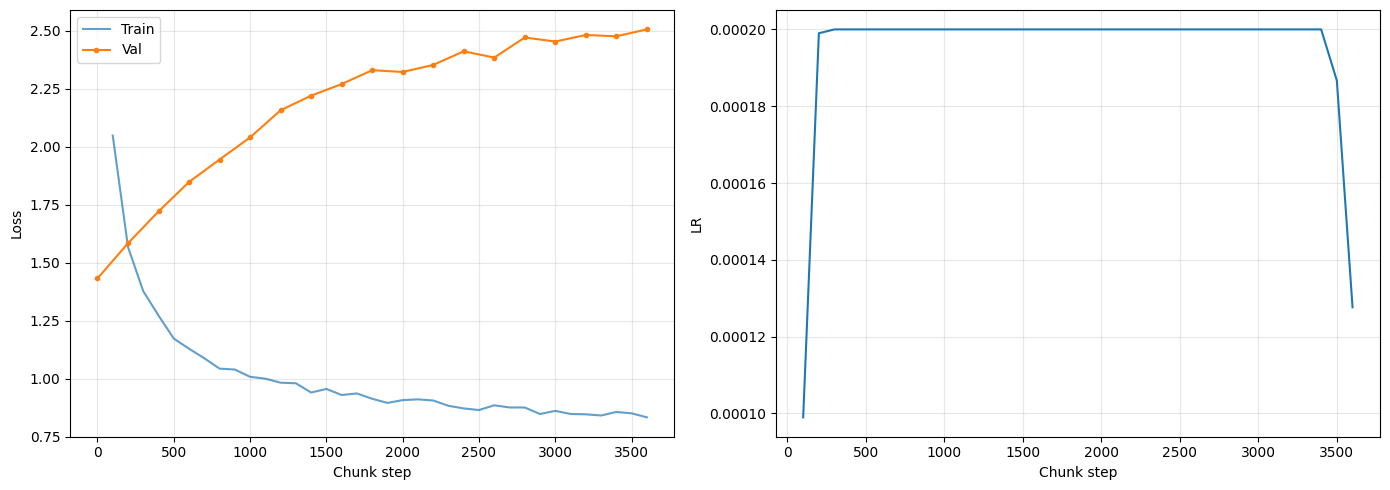

In [10]:
import matplotlib.pyplot as plt
if train_log:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot([d["step"] for d in train_log], [d["loss"] for d in train_log], label="Train", alpha=0.7)
    ax1.plot([d["step"] for d in val_log], [d["val_loss"] for d in val_log], label="Val", marker="o", ms=3)
    ax1.set_xlabel("Chunk step"); ax1.set_ylabel("Loss"); ax1.legend(); ax1.grid(True, alpha=0.3)
    ax2.plot([d["step"] for d in train_log], [d["lr"] for d in train_log])
    ax2.set_xlabel("Chunk step"); ax2.set_ylabel("LR"); ax2.grid(True, alpha=0.3)
    plt.tight_layout(); plt.savefig(LOSS_PLOT_PATH, dpi=150); plt.show()

## 11. Save exported model (final weights of this chunk)

In [11]:
if chunk_completed:
    torch.save({"model_state_dict": raw_model.state_dict(),
        "config": {"arch": "efficient_gqa", "vocab_size": VOCAB_SIZE, "d_model": D_MODEL,
            "n_layers": N_LAYERS, "n_heads": N_HEADS, "n_kv_heads": N_KV_HEADS,
            "d_ff": D_FF, "window_size": WINDOW_SIZE, "chunk_idx": CHUNK_IDX,
            "global_step": GLOBAL_STEP_BASE + completed}
    }, os.path.join(MODEL_OUTPUT_DIR, "model.pt"))
    tokenizer.save_pretrained(MODEL_OUTPUT_DIR)
    print(f"Model saved to {MODEL_OUTPUT_DIR}")
else:
    print("Chunk not finished - skipping export.")

Chunk not finished - skipping export.


In [12]:
fff

NameError: name 'fff' is not defined

## 12. Generation function

In [ ]:
def generate_continuations(prompts, model, tokenizer, device,
                           target_words=128, max_new_tokens=384,
                           temperature=0.5, top_p=0.9, top_k=50,
                           repetition_penalty=1.1, max_input_tokens=None):
    if max_input_tokens is None: max_input_tokens = MAX_SEQ_LEN - max_new_tokens
    model.eval(); results = []
    for prompt in tqdm(prompts, desc="Generating", leave=False):
        ids = tokenizer.encode(prompt, add_special_tokens=False)
        if len(ids) > max_input_tokens: ids = ids[-max_input_tokens:]
        inp = torch.tensor([ids], dtype=torch.long, device=device)
        inp_len = inp.shape[1]
        with torch.no_grad():
            out = model.generate(inp, max_new_tokens=max_new_tokens, temperature=temperature,
                top_p=top_p, top_k=top_k, repetition_penalty=repetition_penalty,
                eos_token_id=tokenizer.eos_token_id)
        gen_text = tokenizer.decode(out[0, inp_len:].tolist(), skip_special_tokens=True)
        results.append(" ".join(gen_text.split()[:target_words]))
    return results

## 13. Generate predictions, save `prediction.json` + submission zip (uses the final weights, uncompiled model)

In [ ]:
RUN_POST = chunk_completed and GENERATE_PREDICTIONS
if not RUN_POST:
    print("Skipping generation (chunk unfinished or GENERATE_PREDICTIONS=False).")
else:
    with open(test_file_path, "r", encoding="utf-8") as f:
        test_data = json.load(f)
    print(f"Test examples: {len(test_data)}")
    raw_model.eval(); predictions = {}
    items = list(test_data.items())
    gen_start = time.time()
    with torch.inference_mode(), torch.amp.autocast("cuda", dtype=torch.float16):
        for idx, (eid, rec) in enumerate(tqdm(items, desc="Generating predictions")):
            cont = generate_continuations([rec["text"]], raw_model, tokenizer, device,
                target_words=TARGET_GENERATION_WORDS, max_new_tokens=MAX_GENERATION_TOKENS,
                temperature=TEMPERATURE, top_p=TOP_P, top_k=TOP_K, repetition_penalty=REPETITION_PENALTY)[0]
            predictions[str(eid)] = {"text": cont}
    gen_time = time.time() - gen_start
    print(f"Generation: {gen_time:.0f}s ({gen_time/len(items):.2f}s/example)")

    with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
        json.dump(predictions, f, ensure_ascii=False, indent=2)
    assert set(str(k) for k in test_data.keys()) == set(predictions.keys()), "ID mismatch!"
    print(f"Saved {len(predictions)} predictions")
    with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
        zipf.write(PREDICTION_PATH, arcname="prediction.json")
    print(f"ZIP: {SUBMISSION_ZIP} ({os.path.getsize(SUBMISSION_ZIP)/1024:.1f} KB)")

    print("=" * 80)
    for eid, rec in list(test_data.items())[:3]:
        pred = predictions[str(eid)]["text"]
        print(f"\nID: {eid}")
        print(f"PROMPT (last 80 words): ...{' '.join(rec['text'].split()[-80:])}")
        print(f"GENERATED ({len(pred.split())} words): {pred[:300]}...")
        print("-" * 80)

## 14. Summary + what to do next session

In [ ]:
print("=" * 70)
print("EFFICIENT GQA TRANSFORMER - CHUNK SUMMARY")
print("=" * 70)
print(f"Architecture: GQA ({N_HEADS}Q/{N_KV_HEADS}KV) + sliding window (w={WINDOW_SIZE}) on even layers, full on odd")
print(f"Parameters (excl. tied embeddings): {unique_params/1e6:.1f}M")
print(f"Chunk {CHUNK_IDX}: peak LR {PEAK_LR:.2e}, steps {completed}/{TOTAL_STEPS}, data mode {DATA_MODE}")
print(f"Cumulative optimizer steps: {GLOBAL_STEP_BASE + completed:,} (~{(GLOBAL_STEP_BASE + completed)*tokens_per_step/1e6:.0f}M tokens)")
print(f"Best val loss this chunk: {best_val_loss:.4f} (chunk step {best_step}) | last val: {val_log[-1]['val_loss']:.4f}" if val_log else "no validation yet")
print(f"Training time this chunk: {total_time/3600:.2f}h")
print("=" * 70)
if chunk_completed:
    print("\nNEXT SESSION - change only these lines in cell 2:")
    print(f"  CHUNK_IDX   = {CHUNK_IDX + 1}")
    print(f'  INIT_CKPT   = "{os.path.basename(FINAL_PATH)}"   # add {FINAL_PATH} as an input of the next session')
    print("  RESUME_CKPT = None")
else:
    print("\nChunk unfinished. Next session: same CHUNK_IDX, keep INIT_CKPT unchanged, and set")
    print(f'  RESUME_CKPT = "{os.path.basename(RESUME_SAVE_PATH)}"   # add {RESUME_SAVE_PATH} as an input')